# Directional Implicit NN From Spring Data

This notebook generates target geometries with `SpringFF`, then trains `NNPotentialFF` with `DirectionalImplicitMultipleSystemOptimizer`. This optimizer avoids exact line minimization, which can be awkward for neural-network potentials.


In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import DirectionalImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import SpringFF, _random_spring_systems, _random_spring_ff_param
from geomatry.ff.NN import NNPotentialFF


In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [3]:
systemN = 20
N = 8
N_pairs = 12
max_Za = 1
fixed_atom_indices = [0,1,2]

Ras, Zas, idx_is, idx_js = _random_spring_systems(systemN, N, N_pairs, max_Za, start_Za=1)
k, r0 = _random_spring_ff_param(max_Za, k_max=2.0, r0_max=1.5)

r0 = r0.clamp(min=0.5, max=1.5)

target_ff = SpringFF(max_Za)
target_ff.reset_parameters(k, r0)
params_star = copy.deepcopy(target_ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target k', k[1:, 1:].mean().item())
print('sample target r0', r0[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target k 0.8368842079598353
sample target r0 0.6492243382322177
sample min distances [0.8655249056099047, 0.6121655278566813, 0.7063600230309024]


In [4]:
# Use SpringFF only to generate target optimized geometries.
target_optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, target_ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
Ra_star_list = target_optimizer.Ra_stars

from geomatry.opt_Energy_approximated.calculator import get_ase_atoms

with torch.no_grad():
    target_energies = torch.stack([
        target_ff.get_E(Ra_star, Za, *graph_builder(get_ase_atoms(Ra_star, Za))).detach()
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ]).float()

# Train the NN force field with directional implicit gradients.
ff = NNPotentialFF(max_Za, hidden_dim=24)
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
params_0 = copy.deepcopy(ff.state_dict())

print('target geometries', len(Ra_star_list))
print('NN parameter tensors', len(params_0))


target geometries 20
NN parameter tensors 18


In [5]:
def predict_system_energy(nn_ff, Ra, Za, graph_builder):
    return nn_ff.get_E(Ra.float(), Za.long(), *graph_builder(get_ase_atoms(Ra, Za)))

def batch_predict(nn_ff):
    return torch.stack([
        predict_system_energy(nn_ff, Ra_star, Za, graph_builder)
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ])
device = torch.device("cpu")
nn_ff = NNPotentialFF(max_Za, hidden_dim=32).to(device)
optimizer = torch.optim.Adam(nn_ff.parameters(), lr=3e-3, weight_decay=1e-6)
loss_history = []

from tqdm import tqdm

epochs = 101
print_period = 100
pbar = tqdm(range(epochs), desc="NN spring training")
for epoch in pbar:
    optimizer.zero_grad()
    y_pred = batch_predict(nn_ff)
    loss = torch.mean((y_pred - target_energies) ** 2)
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

    if epoch % print_period == 0 or epoch == epochs - 1:
        with torch.no_grad():
            errors = batch_predict(nn_ff) - target_energies
            rmse = torch.sqrt(torch.mean(errors ** 2)).item()
            mae = torch.mean(torch.abs(errors)).item()
        pbar.set_postfix(loss=f"{loss.item():.6e}", rmse=f"{rmse:.6f}", mae=f"{mae:.6f}")
        tqdm.write(f"Iteration {epoch}, loss={loss.item():.6e}, rmse={rmse:.6f}, mae={mae:.6f}")

print('training complete')
params_1 = copy.deepcopy(nn_ff.state_dict())


NN spring training:   4%|▍         | 4/101 [00:00<00:05, 16.45it/s, loss=2.175079e+01, mae=4.727881, rmse=5.131432]

Iteration 0, loss=2.175079e+01, rmse=5.131432, mae=4.727881


NN spring training: 100%|██████████| 101/101 [00:05<00:00, 19.72it/s, loss=5.755442e-02, mae=0.203808, rmse=0.235837]

Iteration 100, loss=5.755442e-02, rmse=0.235837, mae=0.203808
training complete


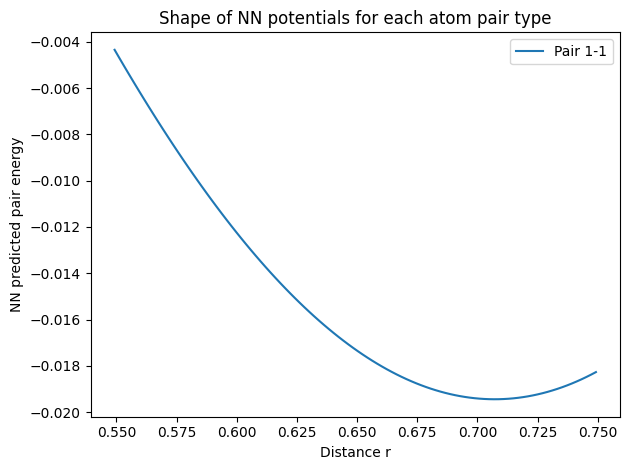

In [6]:
nn_ff.load_state_dict(params_1)

r_vals = torch.linspace(r0[1:, 1:].mean().item()-0.1, r0[1:, 1:].mean().item()+0.1, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()



  0%|          | 0/2001 [00:00<?, ?it/s, total_scale=2.324312e-01]

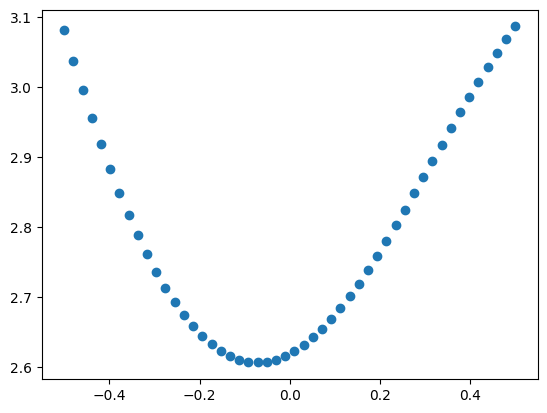

  0%|          | 3/2001 [00:00<03:23,  9.84it/s, total_scale=2.979661e-01]

deviation tensor(-0.0999, dtype=torch.float64, grad_fn=<DivBackward0>)
3.4398088214411304
Fratio -0.41412816774281114
Iteration 0, total_scale: 2.324312e-01


 25%|██▍       | 499/2001 [00:35<01:47, 14.00it/s, total_scale=2.100214e-02]

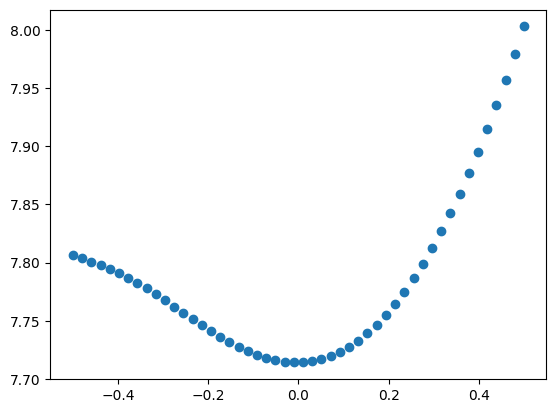

 25%|██▌       | 503/2001 [00:35<02:06, 11.82it/s, total_scale=9.321659e-03]

deviation tensor(-0.0027, dtype=torch.float64, grad_fn=<DivBackward0>)
1.4463691031231765
Fratio -0.29659275920335715
Iteration 500, total_scale: 2.100214e-02


 50%|████▉     | 999/2001 [01:05<00:54, 18.25it/s, total_scale=7.234122e-02]

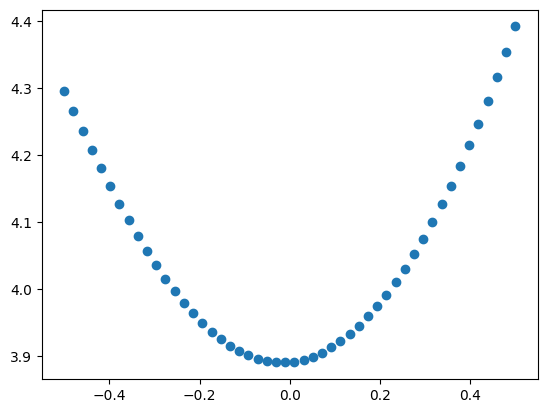

 50%|█████     | 1003/2001 [01:06<01:04, 15.44it/s, total_scale=6.071923e-02]

deviation tensor(-0.0187, dtype=torch.float64, grad_fn=<DivBackward0>)
3.5145598050672593
Fratio -0.08449966999675652
Iteration 1000, total_scale: 7.234122e-02


 75%|███████▍  | 1499/2001 [01:38<00:34, 14.35it/s, total_scale=4.464101e-02]

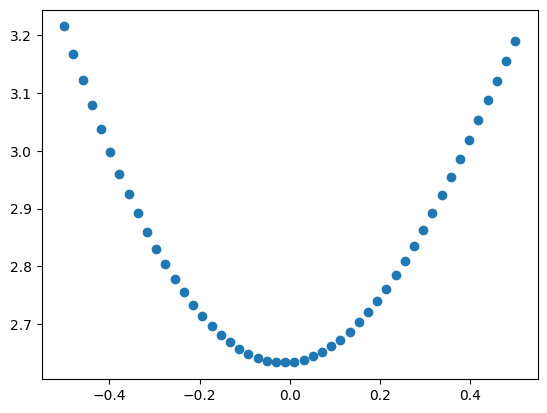

 75%|███████▌  | 1503/2001 [01:38<00:34, 14.25it/s, total_scale=3.602299e-02]

deviation tensor(-0.0162, dtype=torch.float64, grad_fn=<DivBackward0>)
4.319973460528829
Fratio -0.16393934860324666
Iteration 1500, total_scale: 4.464101e-02


100%|█████████▉| 1999/2001 [02:06<00:00, 16.79it/s, total_scale=1.392647e-02]

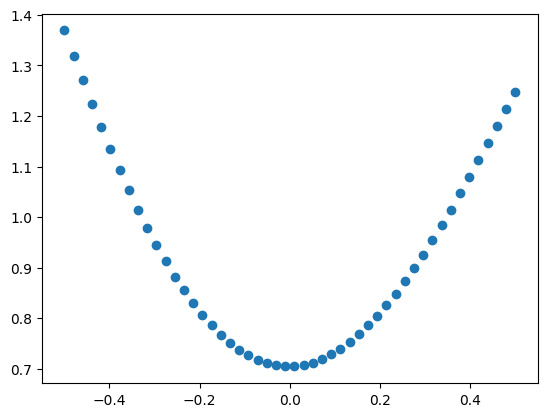

100%|██████████| 2001/2001 [02:07<00:00, 15.75it/s, total_scale=1.392647e-02]

deviation tensor(-0.0037, dtype=torch.float64, grad_fn=<DivBackward0>)
4.507448523231457
Fratio -0.21874214833073985
Iteration 2000, total_scale: 1.392647e-02
optimization complete


In [7]:
params_0 = copy.deepcopy(nn_ff.state_dict())
optimizer = DirectionalImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
new_params = optimizer.optimize(params_0, lr=1e-3, epoch=2001, print_period=500, e_size=0.2, eN=9, sg=2)
print('optimization complete')


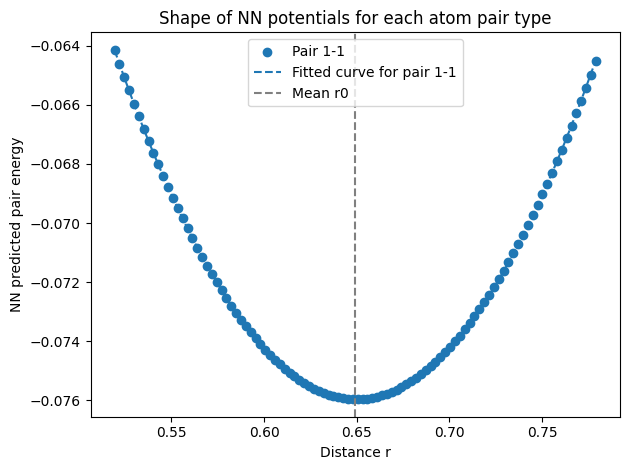

In [8]:
nn_ff.load_state_dict(new_params)

r_vals = torch.linspace(r0[1:, 1:].mean().item()*0.8, r0[1:, 1:].mean().item()*1.2, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        p=np.polyfit(r_vals.numpy(), energies, deg=2)
        plt.scatter(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
        plt.plot(r_vals.numpy(), p[0]*r_vals.numpy()**2 + p[1]*r_vals.numpy() + p[2], label=f'Fitted curve for pair {i}-{j}', linestyle='--')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.axvline(x=r0[1:, 1:].mean().item(), color='gray', linestyle='--', label='Mean r0')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()
